<a href="https://colab.research.google.com/github/youngseo21/esaa_22/blob/main/assignment_120922_dimension_reduction(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **04 SVD(Singular Value Decomposition)**
____

### | **SVD ??**
___
- SVD ?? PCA? ??? ?? ?? ??? ????. PCA? ?? ????? ??? ? ???, SVD? ???? ?? ??? ?? ?? ??? ?? ???? ??? ? ??.
- ????? SVD? m x n ?? A? ??? ?? ???? ?? ???.
$$ A = UDV^T$$
  + U, V : square matrix(m x m, n x n) consisting of singular vectors
  + D : diagonal matirx consisting of singular value

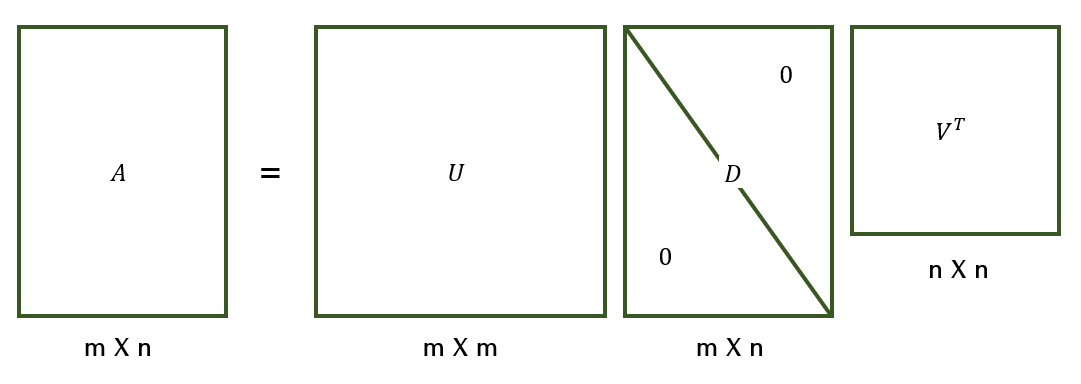

- ??? ????? ??? ?? D? ???? ??? ?? ?? ? singular value? 0? ??? ?? ???? ??? D? ???? U? V ??? ?? ??? ??? ?? ??? SVD? ????.

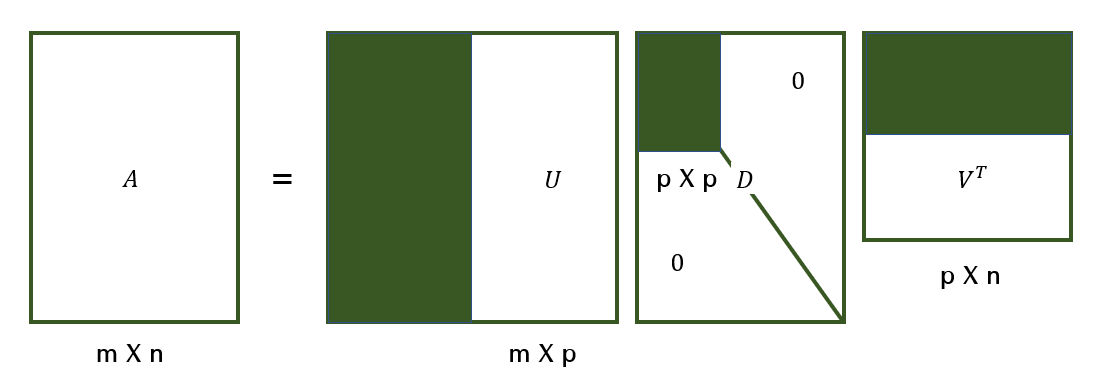

- Truncated SVD? D? ?? ?? ? ?? ? ?? ???, ??? ???? U? V? ??? ?? ??? ?? ??? ?? ??? ???? ???.
- ???? SVD? ?? ???? ???? ?????? ??? ????.
- ???? SVD? ??? SVD ??? ????, SVD ??? ?? ??? ?????? ??? ??? ?? ????.


In [ ]:
# numpy? SVD ?? import
import numpy as np
from numpy.linalg import svd

# 4X4 Random ?? a ??(?? row ??? ??? ??) 
np.random.seed(121)
a = np.random.randn(4,4)
print(np.round(a, 3))

- ??? ??? a ??? SVD? ???, `U`, `Sigma`, `Vt`? ????.
- SVD ??? `numpy.linalg.svd`? ????? ?? ??? ???? U ??, sigma ??, V ?? ??? ????.
  + sigma ??? ??, ?? ??? 1?? ??? ????.

In [ ]:
U, Sigma, Vt = svd(a)
print(U.shape, Sigma.shape, Vt.shape)
print('U matrix : \n', np.round(U, 3))
print('Sigma Value : \n', np.round(Sigma, 3))
print('V transpose matrix : \n', np.round(Vt, 3))

- ??? U, Sigma, Vt? ?? ?? ??? ??? ????? ?????.
- ?, Sigma? ?? ??? ??? ????, ?? 0? ??? ?? ??? ??? ?, ??? ??? ?? ??.

In [ ]:
# Sigma? ?? 0? ??? ????? ??
Sigma_mat = np.diag(Sigma)

a_ = np.dot(np.dot(U, Sigma_mat), Vt)
print(np.round(a_, 3))

- U, Sigma, VT? ??? `a_`? ?? ?? a? ???? ???? ? ? ??.
- ???? ????? row ? ???? ?? ??, sigma ?? ??? ???, ?? ?? ?? ??? ??? ? ??? ????.
  + ??? ???? ???? ??, a ??? 3?? ?? '? ?? ? + ??? ?`?? ??????, 4?? ?? ? ?? ?? ?? ??????.

In [ ]:
a[2] = a[0] + a[1]
a[3] = a[0]
print(np.round(a,3))

In [ ]:
# ?? SVD? ???? Sigma ? ?? 
U, Sigma, Vt = svd(a)
print(U.shape, Sigma.shape, Vt.shape)
print('Sigma Value :\n',np.round(Sigma,3))

- ??? ??? ???, Sigma ? ? 2?? 0?? ???.
- ?, Linearly independet? ?? ??? 2??? ????.(??? Rank? 2??.)
- ??? ??? U, Sigma, Vt? ??? ?? ?? ??? ?????.
- ???? U, Sigma, Vt ?? ???? ???? ??, Sigma? 0? ???? U, Sigma, Vt ???? ???? ????.
  + Sigma? ??, ?? 2? ??? 0? ????, 
  + U ?? ? ?? ? ?? ?? ????,
  + Vt? ?? ? ?? ?? ???? ????.

In [ ]:
# U ??? ??? Sigma? ??? ????? Sigma? ? 2?? ???? ? 2?? ??
U_ = U[:, :2]
Sigma_ = np.diag(Sigma[:2])

# V ?? ??? ??? ? 2?? ??
Vt_ = Vt[:2]
print(U_.shape, Sigma_.shape, Vt_.shape)

# U, Sigma, Vt? ??? ????, ?? ?? ?? ??
a_ = np.dot(np.dot(U_,Sigma_), Vt_)
print(np.round(a_, 3))

- ???? Truncated SVD? ??? ??? ?????.
- Truncated SVD? D ??? ?? ?? ??(singular value) ? ?? ?? ???? ??? ???? ????.
- ??? ???? ????? ? ?? ???? ???? ???, ?? ??? ???? ??? ?? ??. ??? ??? ???? ?? ??? ??? ? ??. ?? ??? ??? ??? ?????(Truncate) ?? ??? ? ??? ??? ? ??.
- Truncated SVD? ???? ??? ??? ??? ??????. ?????? ???? ???.
- ????? ????? SVD? `scipy.linalg.svd`? ???? ???, Truncated SVD? ?? ??? ????, `scipy.sparse.linalg.svds`? ???? ??.
- ??? 6x6 ?? ??? Normal SVD? ????, ??? ??? ??? Sigma ?? ?? ???? ??? ?, ?? Truncated SVD? ??? ??? ??? ??, SiSigma ?? ?? ???, ??? Truncated SVD? ??? ??? ??? ???? ?? ??? ?????.

In [ ]:
import numpy as np
from scipy.sparse.linalg import svds
from scipy.linalg import svd

# ?? ??? ????, SVD? ??? ?? U, Sigma, Vt? ?? ?? 
np.random.seed(121)
matrix = np.random.random((6, 6))
print('?? ?? :\n',matrix)

# Normal SVD
U, Sigma, Vt = svd(matrix, full_matrices = False)
print('\n?? ?? ?? : ',U.shape, Sigma.shape, Vt.shape)
print('\nSigma? ?? : ', Sigma)

# Sigma ??? ???? 4?? ?? Truncated SVD ?? 
num_components = 4
U_tr, Sigma_tr, Vt_tr = svds(matrix, k = num_components)
print('\nTruncated SVD ?? ?? ?? : ',U_tr.shape, Sigma_tr.shape, Vt_tr.shape)
print('\nTruncated SVD Sigma? ?? : ', Sigma_tr)
matrix_tr = np.dot(np.dot(U_tr,np.diag(Sigma_tr)), Vt_tr)  # output of TruncatedSVD

print('\nTruncated SVD? ?? ? ?? ?? :\n', matrix_tr)

- 6 x 6 ??? SVD ????, U, Sigma, Vt? ?? (6, 6) (6,) (6, 6) ?????, Truncated SVD? `n_components`? 4? ??? ????, U, Sigma, Vt? ?? (6, 4) (4,) (4, 6) ????.
- Truncated SVD? ??? ??? ?? ????, ???? ???? ??, ?? ??? ????? ???? ? ? ??.

### | **???? TruncatedSVD ???? ??? ??**
___
- ????? `TruncatedSVD` ???? ????? `svds`? ?? Truncated SVD ??? ??? ?? ??? ??? U, Sigma, Vt ??? ????? ???.
- ????? `TruncatedSVD` ???? `PCA` ???? ????, `fit()`? `transform()`? ??? ?? ???? ? ?? ?? ????? ??? ??? ????.
- ?? ???? Truncated SVD ???? ??? U*Sigma ??? ?? ??? ?? ????.

In [ ]:
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
%matplotlib inline

iris = load_iris()
iris_ftrs = iris.data

# 2?? ?? component? TruncatedSVD ??
tsvd = TruncatedSVD(n_components = 2)
tsvd.fit(iris_ftrs)
iris_tsvd = tsvd.transform(iris_ftrs)

# Scatter plot 2???? TruncatedSVD ?? ? ??? ??. ??? ??? ??
plt.scatter(x = iris_tsvd[:,0], y = iris_tsvd[:,1], c = iris.target)
plt.xlabel('TruncatedSVD Component 1')
plt.ylabel('TruncatedSVD Component 2')

- ?? ??? `TruncatedSVD`? ??? ?? ??????.
- `TruncatedSVD` ?? ?? PCA? ???? ?? ?, ???? ?? ?? ?????? ??? ??? ? ?? ???? ??? ???? ??? ??.
- ????? `TruncatedSVD`? `PCA` ??? ????? ??? ??, ? ??? ?? SVD? ??? ??? ????.
- ?? ???? ????? ?, `TruncatedSVD`? `PCA` ??? ??? ???, ? ?? ?? ??? ?? ? ? ??.

In [ ]:
from sklearn.preprocessing import StandardScaler

# iris ???? StandardScaler? ??
scaler = StandardScaler()
iris_scaled = scaler.fit_transform(iris_ftrs)

# ????? ???? ???? TruncatedSVD ?? ?? 
tsvd = TruncatedSVD(n_components = 2)
tsvd.fit(iris_scaled)
iris_tsvd = tsvd.transform(iris_scaled)

# ????? ???? ???? PCA ?? ?? 
pca = PCA(n_components = 2)
pca.fit(iris_scaled)
iris_pca = pca.transform(iris_scaled)

# TruncatedSVD ?? ???? ???, PCA?? ???? ???? ?? 
fig, (ax1, ax2) = plt.subplots(figsize = (9,4), ncols = 2)
ax1.scatter(x = iris_tsvd[:,0], y = iris_tsvd[:,1], c = iris.target)
ax2.scatter(x = iris_pca[:,0], y = iris_pca[:,1], c = iris.target)
ax1.set_title('Truncated SVD Transformed')
ax2.set_title('PCA Transformed')

- ? ?? ?? ?? ?? ?? ?? ? ???? ???? ??? ????? ?? ?? ?? ? ? ??.

In [ ]:
print((iris_pca - iris_tsvd).mean())
print((pca.components_ - tsvd.components_).mean())

- ?? 0? ??? ????, 2?? ??? ?? ??? ?? ? ? ??.
- ?, ????? ?????? ??? ??? ?????, ????? SVD? PCA? ??? ??? ????. ?? PCA? SVD ?????? ?????? ????.
- ??? PCA? Dense Matrix? ?? ??? ????, SVD? Sparse Matrix? ?? ??? ????.
- SVD? PCA? ????, ??? ?? ???? ??? ??? ?? ?? ??? ?? ?? ??? ????. ?? ???? ?? ??? ??? LSA(Latent Semantic Analysis)? ?? ??????.

## **05 NMF(Non-Negative Matrix Factorization)**
____

### | **NMF ??**
___
- NMF? Truncated SVD? ?? ?? ??? ?? ?? ??(Low-Rank Approximation) ??? ????.
- NMF? ?? ?? ?? ?? ?? ?? ?? ??(0 ??)?? ?? ????, ??? ?? ? ? ???? ? ?? ?? ?? ??? ??? ? ?? ??? ????.


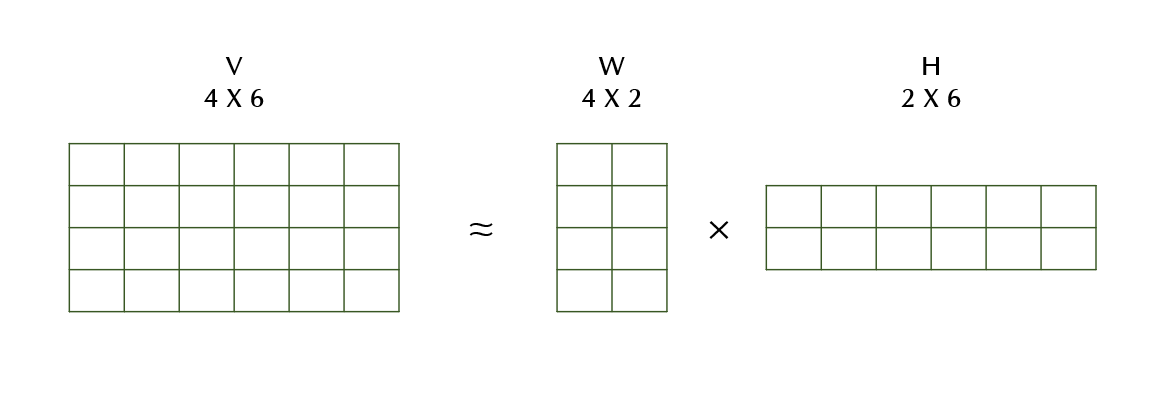

- 4 X 6 ?? ?? V? W? H? ??? ??? ? ??.
- ?? ??(Matrix Facotorization)? ????? SVD? ?? ?? ?? ??? ????.
- ??? ?? ??? ??, ?? ??? ? ??? ?? ? ???? ?? ?? W? ?? ??? ? ???? ??, ? ??? ?? ?? H? ????.
- ??? ??? ??? ?? ??? ???? ??? ??.
- ?? ?? W? ?? ?? ??? ? ?? ??? ?? ??? ???? ????, ?? ?? H? ? ?? ??? ?? ?(?? ??)? ??? ?????? ????.
- NMF? SVD? ????, ?? ??? ?? ?? ??? ????, ??? ?? ? ??, ???? ?? ?? ?? ??? ???? ??.
- ?????? NMF? `NMF` ???? ?? ????.
- ?? ???? NMF? ??? 2?? ????? ????, ?? ??????.

In [ ]:
from sklearn.decomposition import NMF
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
%matplotlib inline

iris = load_iris()
iris_ftrs = iris.data

nmf = NMF(n_components = 2)
nmf.fit(iris_ftrs)
iris_nmf = nmf.transform(iris_ftrs)

plt.scatter(x = iris_nmf[:,0], y = iris_nmf[:,1], c = iris.target)
plt.xlabel('NMF Component 1')
plt.ylabel('NMF Component 2')

- NMF? SVD? ???? ??? ??? ?? ?? ??, ???? ?? ??? ??, ?? ??? ? ?????? ? ????. ?? ?? ??? ?? Recommendations ??? ???? ????.
  + ?? ??(Latent Factoring) ??? ?? ?? : ???? ?? ?? ????? ???-?? ?? ????? ?? ?? ??? ?? ?????, ???? ???? ?? ??? ?? ???? ??? ??? ?? ?? ?? ??(Rating)? ????, ?? ??? ??? ??? ????? ??